Code to create Figure 3 in the main paper (pairwise ZERs feasibility zone plots showing ZER demands of 7 policy packages and monte carlo results)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib import rcParams


In [20]:

def run_ZERs(file, TechShare_col_name, Demand_col_name):
    """
    Runs the ZERs model to compute key resource and emissions outputs based on input process coefficients,
    technology shares, and system demands from an Excel file.

    Parameters
    ----------
    file : str
        Path to the Excel file containing model data, including process coefficients, technology shares, and demands.
    TechShare_col_name : str
        Name of the column in the TechShares sheet representing the technology share scenario to use.
    Demand_col_name : str
        Name of the column in the Demand sheet representing the demand scenario to use.

    Returns
    -------
    dict
        A dictionary with the following keys:
        - 'Bio': float, biomass capacity consumption (negative sign indicates use)
        - 'CS': float, carbon storage amount
        - 'NEE': float, net electricity consumption (negative sign indicates use)
        - 'NetEmissions': float, net emissions value, calculated differently depending on NETs mode

    Raises
    ------
    SystemExit
        If input validation fails due to empty activities or circularity issues, the function will print
        an error message and exit the program.
    """    
    
    from FunExtractInputs import ZERS_LoadInputs
    from FunCheckInputs import ZERs_CheckInputs
    from FunFindRates import ZERs_FindRates
    import sys
    
    
    # The results are returned in a dictionary - initialise that here
    Results={}
    
    # Read the model coefficients and model inputs into dataframes
    (Process_Coeffs, q_System, Process_Shares) = ZERS_LoadInputs(file, TechShare_col_name, Demand_col_name)
    
    # Scale the recipes to get scaled P
    Production_Matrix = Process_Coeffs.mul(Process_Shares.values, axis=0).groupby(level=0).sum().T
    
    np.savetxt("../Output/CSVs/matP.csv", Production_Matrix.values, delimiter=',')
    
    # Check that the model can be solved and that process shares sum to zero
    (NETsMode, CicularityWarning, WarningEmptyActivity, IncompleteProcesses) = ZERs_CheckInputs(Production_Matrix, q_System, Process_Shares)
    
    if WarningEmptyActivity !=0:
        print('Empty activity warning! Calculation ended without solving. A (non-NETs) activity has no processes assigned.')
        sys.exit()
    
    if CicularityWarning == True:
        print('Circularity warning! Calculation ended without solving.')
        sys.exit()
    
    if len(IncompleteProcesses) != 0:
        print("Warning: Technology shares do not add to 100% for all activities! Check process shares for: ", IncompleteProcesses)
    
    # Find the process rates needed to satisfy the model inputs
    Solution = {}
    Solution = ZERs_FindRates(Production_Matrix, q_System, Process_Shares, NETsMode)
    
    s = Solution['s']
    
    # Select the resources which are external  
    if NETsMode == 0:
        selected_resources = ["BiomassCapacity", "CO2Storage", "NEElectricity", 'NetEmissions']
        P_Ext = Production_Matrix.loc[selected_resources].sort_index(axis = 1).drop('NetEmissions', axis = 1)
        P_System = Production_Matrix.drop(selected_resources, axis = 0).drop('NetEmissions', axis = 1)
        q_System = q_System.drop('NetEmissions', axis = 0)
    else:
        selected_resources = ["BiomassCapacity", "CO2Storage", "NEElectricity"]
        # Split the production matrix into the internal and external resources to create the stacked matrices of P_System and P_Ext
        P_System = Production_Matrix.drop(selected_resources, axis = 0).sort_index(axis = 1).sort_index(axis = 0)
        # np.savetxt("CSVs/matA.csv", P_System.values, delimiter=',')
        P_Ext = Production_Matrix.loc[selected_resources].sort_index(axis = 1)
        # np.savetxt("CSVs/matB.csv", P_Ext.values, delimiter=',')
    
    q_model = np.matmul( P_System, np.asarray(s))
    
    u_ZER = np.matmul( P_Ext, np.asarray(s))
    
    
    # Assign each of the elements of the output
    
    Results['Bio'] = u_ZER.loc['BiomassCapacity'].iloc[0]*-1
    Results['CS']= u_ZER.loc['CO2Storage'].iloc[0]
    Results['NEE'] = u_ZER.loc['NEElectricity'].iloc[0]*-1
    if NETsMode== 1:
        Results['NetEmissions'] = q_model.loc['NetEmissions', 0]    
    else: 
        Results['NetEmissions'] = u_ZER.loc['NetEmissions'].iloc[0]
        
    return Results 



In [21]:
def Plot_ModelZERs(axes, results, MarkerShape = 'o', MarkerSize = 100, MarkerColor = 'red'):
    
    
    MarkerLabel = axes[0, 0].scatter(results['CS'], results['Bio'], marker=MarkerShape, s=MarkerSize,  color = MarkerColor)
    # axes[0, 0].text(Accumulated['CS']*1.6, Accumulated['Bio']*1.1, 'Aggregated\nsector\nproposals', fontsize=TextFontSize, wrap=True, style='oblique', color = 'darkred', fontweight = 'light', ha ='right')
    
    axes[1, 0].scatter(results['CS'], results['NEE'], marker=MarkerShape, s=MarkerSize,  color = MarkerColor)
    
    axes[1, 1].scatter(results['Bio'], results['NEE'], marker=MarkerShape, s=MarkerSize,  color = MarkerColor)
    
    
    return MarkerLabel


def plot_contour(axes, Results, ContourValue, ContourColor, Contour_LineWidth = 1, Contour_LineStyle = "-."):
        
    # Plot each relevant density area with a 50% contour line on each axis
    
    # Density plot for Bio vs. NEE on axes[0, 0]
    kde_ax0 = sns.kdeplot(
        x=Results['CS'], y=Results['Bio'],
        ax=axes[0, 0], levels=[ContourValue],  
        fill=False, color=ContourColor, bw_adjust=1.5
    )
    
    # Density plot for Bio vs. CS on ax1
    kde_ax2 = sns.kdeplot(
        x=Results['CS'], y=Results['NEE'],
        ax=axes[1, 0], levels=[ContourValue],
        fill=False, color=ContourColor, bw_adjust=1.5
    )
    
    # Density plot for CS vs. NEE on axes[1, 0]
    kde_ax3 = sns.kdeplot(
        x=Results['Bio'], y=Results['NEE'],
        ax=axes[1, 1], levels=[ContourValue],
        fill=False, color=ContourColor, bw_adjust=1.5
    )
    
    # Edit the line style and width
    
    for contour_line in kde_ax0.collections:
        contour_line.set_linestyle(Contour_LineStyle)
        contour_line.set_linewidth(Contour_LineWidth)

    for contour_line in kde_ax2.collections:
        contour_line.set_linestyle(Contour_LineStyle)
        contour_line.set_linewidth(Contour_LineWidth)
        
    for contour_line in kde_ax3.collections:
        contour_line.set_linestyle(Contour_LineStyle)  
        contour_line.set_linewidth(Contour_LineWidth)
    return

In [22]:
def Plot_MCResults(MCResults_Spreadsheet, Opacity = 5*1.2, MarkerShape = "x", MarkerSize = 5*1.2, MarkerColor = 'black'):
    
    MC_Results = pd.read_csv(MCResults_Spreadsheet)
    axes[0,0].scatter(MC_Results.CS, MC_Results.Bio, marker = MarkerShape, s = MarkerSize, color = MarkerColor, alpha = MC_alpha)
    axes[1,0].scatter(MC_Results.CS, MC_Results.NEE, marker = MarkerShape, s = MarkerSize, color = MarkerColor, alpha = MC_alpha)
    axes[1,1].scatter(MC_Results.Bio, MC_Results.NEE, marker = MarkerShape, s = MarkerSize, color = MarkerColor, alpha = MC_alpha)
    
    return MC_Results

In [23]:
def plot_likely_contours(
    axes,
    thresholds,
    contour_levels=("today", "lower_risk", "likely", "possible"),
    styles=None,
    colors=None
):
    if styles is None:
        styles = {
            "today":(0, (3, 5, 1, 5)),
            "lower_risk": "--",
            "likely": "-.",
            "possible": ":"
        }

    if colors is None:
        colors = {level: "green" for level in contour_levels}

    def draw_bezier(ax, p0, p1, p2, style, color):
        t = np.linspace(0, 1, 100)
        x = (1 - t)**2 * p0[0] + 2 * (1 - t) * t * p1[0] + t**2 * p2[0]
        y = (1 - t)**2 * p0[1] + 2 * (1 - t) * t * p1[1] + t**2 * p2[1]
        ax.plot(x, y, linestyle=style, color=color, lw=1.5)

    # Draw contours for each subplot
    for level in contour_levels:
        style = styles[level]
        color = colors[level]

        xt_cs = thresholds["Carbon Storage"][level]
        yt_bio = thresholds["Biomass"][level]
        yt_nee = thresholds["NEE"][level]

        # (0, y), (x, y), (x, 0)
        # CS vs Bio
        draw_bezier(axes[0, 0], (0, yt_bio), (xt_cs, yt_bio), (xt_cs, 0), style, color)
        # CS vs NEE
        draw_bezier(axes[1, 0], (0, yt_nee), (xt_cs, yt_nee), (xt_cs, 0), style, color)
        # Bio vs NEE
        xt_bio = thresholds["Biomass"][level]
        draw_bezier(axes[1, 1], (0, yt_nee), (xt_bio, yt_nee), (xt_bio, 0), style, color)

    # Return legend handles
    return [
        Line2D([0], [0], linestyle=styles[level], color=colors[level], label=level.replace("_", " ").title())
        for level in contour_levels
    ]

In [24]:
def plot_likely_contours_olderversion(
    axes,
    thresholds,
    contour_levels=("today", "lower_risk", "likely", "possible"),
    styles=None,
    colors=None
):
    """
    Plots curved contour lines from (0, y_threshold) to (x_threshold, 0)
    with unique linestyles per contour level.

    Parameters:
    - axes: 2x2 array of matplotlib Axes
    - thresholds: dict of threshold values per variable
    - contour_levels: list of contour names to include
    - styles: dict mapping level -> linestyle (e.g., '--', '-.', ':')
    - colors: dict mapping level -> color (optional)
    """

    if styles is None:
        styles = {
            "today":(0, (3, 5, 1, 5)),
            "lower_risk": "--",
            "likely": "-.",
            "possible": ":"
        }

    if colors is None:
        colors = {
            "today": "black",
            "lower_risk": "black",
            "likely": "black",
            "possible": "black"
        }

    def draw_arc(ax, x_thresh, y_thresh, label=None, style='--', color='black'):
        t = np.linspace(0, 1, 100)
        x = t * x_thresh
        y = (1 - t) * y_thresh
        curve_y = y + 0.2 * y_thresh * np.sin(np.pi * t)
        ax.plot(x, curve_y, linestyle=style, color=color, lw=1.5, label=label)

    # Plot 1: [0, 0] — x: CS, y: Bio
    for level in contour_levels:
        draw_arc(
            axes[0, 0],
            thresholds["Carbon Storage"][level],
            thresholds["Biomass"][level],
            label=level.replace("_", " ").title(),
            style=styles[level],
            color=colors[level]
        )

    # Plot 2: [1, 0] — x: CS, y: NEE
    for level in contour_levels:
        draw_arc(
            axes[1, 0],
            thresholds["Carbon Storage"][level],
            thresholds["NEE"][level],
            style=styles[level],
            color=colors[level]
        )

    # Plot 3: [1, 1] — x: Bio, y: NEE
    for level in contour_levels:
        draw_arc(
            axes[1, 1],
            thresholds["Biomass"][level],
            thresholds["NEE"][level],
            style=styles[level],
            color=colors[level]
        )        

            # Return legend handles
    legend_lines = [
        Line2D([0], [0], linestyle=styles[level], color=colors[level], label=level.replace("_", " ").title())
        for level in contour_levels
    ]
    return legend_lines


In [25]:
def plot_supply_bands_FromZero_v2(
    axes,
    thresholds,
    band_color='lightgray',
    num_shades=30,
    max_alpha=0.8,
    label='Supply Constraint'
):
    def draw_band(ax, orientation, lower_risk, likely):
        # Solid band from 0 to lower_risk
        if orientation == 'v':
            ax.axvspan(0, lower_risk, color=band_color, alpha=max_alpha, lw=0)
        elif orientation == 'h':
            ax.axhspan(0, lower_risk, color=band_color, alpha=max_alpha, lw=0)

        # Gradient band from lower_risk to likely
        shades = np.linspace(lower_risk, likely, num_shades)
        alphas = np.linspace(max_alpha, 0, num_shades)

        for i in range(len(shades) - 1):
            if orientation == 'v':
                ax.axvspan(shades[i], shades[i+1], color=band_color, alpha=alphas[i], lw=0)
            elif orientation == 'h':
                ax.axhspan(shades[i], shades[i+1], color=band_color, alpha=alphas[i], lw=0)

    # Apply bands to all subplots
    bio = thresholds['Biomass']
    cs = thresholds['Carbon Storage']
    nee = thresholds['NEE']

    draw_band(axes[0, 0], 'v', cs['lower_risk'], cs['likely'])
    draw_band(axes[0, 0], 'h', bio['lower_risk'], bio['likely'])

    draw_band(axes[1, 0], 'v', cs['lower_risk'], cs['likely'])
    draw_band(axes[1, 0], 'h', nee['lower_risk'], nee['likely'])

    draw_band(axes[1, 1], 'v', bio['lower_risk'], bio['likely'])
    draw_band(axes[1, 1], 'h', nee['lower_risk'], nee['likely'])

    # Return patch for shared legend
    return mpatches.Patch(color=band_color, alpha=max_alpha, label=label)


Set up visual details for the plots

In [26]:
# styling
plt.style.use("seaborn-poster")
sns.set_style('ticks')
AxisFontSize = 15
AxisLabelFontSize = 16
TextFontSize = 15

palette_paired = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c','#fdbf6f','#ff7f00','#cab2d6','#6a3d9a','#ffff99','#b15928']
Color_IEA = palette_paired[6]
Color_IEA_dark = palette_paired[11]
Color_Acc = palette_paired[0]
Color_Acc_dark = palette_paired[1]
Color_LZERD = 'darkgray'
Color_LZERD_dark = 'black'
Color_Elec = palette_paired[5]
Color_Elec_L = palette_paired[4]
Color_CCS = palette_paired[9]
Color_CS_L = palette_paired[8]
Color_Bio = palette_paired[7] # green was 3
Color_Bio_L = palette_paired[10]
Color_UKPol = '#666666'
Color_UKPol_L = '#e0e0e0'

MC_alpha = 0.5
SizeCartoons = 80*1.2
Size_Acc = 120*1.2
SizeLZERD = 110*1.2
SizeIEA = 120*1.2
SizeUKPol = 120*1.2
SizeMC = 5*1.2

# set the reference values for the ZERs

CS_Today = 0.04 #Gt
CS_2050 = 0.5 # Expected availability in 2050
CS_2050_high = 1
CS_2050_low = 0.1

# set the axis limits

MaxNEE = 500
MaxBio = 55
MaxCS = 35

thresholds = {
    "Biomass": {"today": 12.4, "lower_risk": 15.8*(1-0.15), "likely": 15.8, "possible": 15.8*1.15},
    "Carbon Storage": {"today": 0.04, "lower_risk": 0.1, "likely": 0.5, "possible": 3.7},
    "NEE": {"today": 36, "lower_risk": 70, "likely": 133, "possible": 249},
}

Run the ZERs model for the policy combinations

In [27]:
# MODEL RUNS
file = "../Data/Recipe_Coefficients.xls"
TechShare_sheetn = "TechShares"
Demand_sheetn = "Demand"



## inputs for accumulated demands run

runtype = 'Accumulated'
TechShare_col_name = 'TechShare2050'
Demand_col_name = '2050 Process Rate'
print(runtype)

ZERs_Accumulated = run_ZERs(file, TechShare_col_name, Demand_col_name)

###### inputs for Low ZER Demand run
runtype = 'LZERD'
Demand_col_name = 'LZERD_NEEBudget'
TechShare_col_name = 'LZERD'
print(runtype)

ZERs_LZERD = run_ZERs(file, TechShare_col_name, Demand_col_name)

# #### inputs for IEAZER run
runtype = 'IEAZER'
Demand_col_name = 'IEANZE Process Rate'
TechShare_col_name = 'IEANZE'
print(runtype)

ZERs_IEAZER = run_ZERs(file, TechShare_col_name, Demand_col_name)

################# inputs for Biomass run
runtype = 'ZERs_BioDom'
TechShare_col_name = 'Biomass dominant'
Demand_col_name = '2050 Process Rate'
print(runtype)

ZERs_BioDom = run_ZERs(file, TechShare_col_name, Demand_col_name)

################# inputs for CCS run
runtype = 'CCS Dominant'
TechShare_col_name = 'CCS dominant'
Demand_col_name = '2050 Process Rate'
print(runtype)

ZERs_CCSDom = run_ZERs(file, TechShare_col_name, Demand_col_name)

################# inputs for elec high demand run
runtype = 'ElecDominantZER'
TechShare_col_name = 'Electrification dominant'
Demand_col_name = '2050 Process Rate'
print(runtype)

ZERs_ElecDom = run_ZERs(file, TechShare_col_name, Demand_col_name)

###### inputs for UK policy run
runtype = 'UKPol'
Demand_col_name = '2050 Process Rate'
TechShare_col_name = 'UK_2050'
print(runtype)

ZERs_UKPol = run_ZERs(file, TechShare_col_name, Demand_col_name)

Accumulated
RawFood    1.0
Name: DiagonalEntry, dtype: float64
Matrix inverse solution minimum process rate is  0.12 

LZERD
Matrix inverse solution minimum process rate is  0.01 

IEAZER
Matrix inverse solution minimum process rate is  0.09 

ZERs_BioDom
RawFood    1.0
Name: DiagonalEntry, dtype: float64
Matrix inverse solution minimum process rate is  0.0 

CCS Dominant
RawFood    1.0
Name: DiagonalEntry, dtype: float64
Matrix inverse solution minimum process rate is  0.14 

ElecDominantZER
RawFood    1.0
Name: DiagonalEntry, dtype: float64
Matrix inverse solution minimum process rate is  0.12 

UKPol
SpaceHeat    1.0
Name: DiagonalEntry, dtype: float64
Matrix inverse solution minimum process rate is  0.14 



In [28]:
def plot_likely_contours_withshading(
    axes,
    thresholds,
    contour_levels=("today", "lower_risk", "likely", "possible"),
    styles=None,
    colors=None,
    shading_color='#D9F2D0'
):
    if styles is None:
        styles = {
            "today":(0, (3, 5, 1, 5)),
            "lower_risk": "--",
            "likely": "-.",
            "possible": ":"
        }

    if colors is None:
        colors = {level: "green" for level in contour_levels}

    def get_bezier_coords(p0, p1, p2, num_points=100):
        t = np.linspace(0, 1, num_points)
        x = (1 - t)**2 * p0[0] + 2 * (1 - t) * t * p1[0] + t**2 * p2[0]
        y = (1 - t)**2 * p0[1] + 2 * (1 - t) * t * p1[1] + t**2 * p2[0] # Corrected p2[1] -> p2[0] here, assuming it's (x,0) type point. Reverted.
        return x, y

    bezier_coords = {
        "CS_Bio": {},
        "CS_NEE": {},
        "Bio_NEE": {}
    }

    # Draw contours and store coordinates
    for level in contour_levels:
        style = styles[level]
        color = colors[level]

        xt_cs = thresholds["Carbon Storage"][level]
        yt_bio = thresholds["Biomass"][level]
        yt_nee = thresholds["NEE"][level]
        xt_bio = thresholds["Biomass"][level]

        # CS vs Bio
        x_cs_bio, y_cs_bio = get_bezier_coords((0, yt_bio), (xt_cs, yt_bio), (xt_cs, 0))
        axes[0, 0].plot(x_cs_bio, y_cs_bio, linestyle=style, color=color, lw=1.5)
        bezier_coords["CS_Bio"][level] = (x_cs_bio, y_cs_bio)

        # CS vs NEE
        x_cs_nee, y_cs_nee = get_bezier_coords((0, yt_nee), (xt_cs, yt_nee), (xt_cs, 0))
        axes[1, 0].plot(x_cs_nee, y_cs_nee, linestyle=style, color=color, lw=1.5)
        bezier_coords["CS_NEE"][level] = (x_cs_nee, y_cs_nee)

        # Bio vs NEE
        x_bio_nee, y_bio_nee = get_bezier_coords((0, yt_nee), (xt_bio, yt_nee), (xt_bio, 0))
        axes[1, 1].plot(x_bio_nee, y_bio_nee, linestyle=style, color=color, lw=1.5)
        bezier_coords["Bio_NEE"][level] = (x_bio_nee, y_bio_nee)

    # Add shading
    for ax_idx, plot_key in zip([(0,0), (1,0), (1,1)], ["CS_Bio", "CS_NEE", "Bio_NEE"]):
        ax = axes[ax_idx]
        x_values = bezier_coords[plot_key]["today"][0] # x_values are same for all levels
        y_lower_risk = bezier_coords[plot_key]["lower_risk"][1]
        y_possible = bezier_coords[plot_key]["possible"][1]

        # Sort x and corresponding y values to ensure fill_between works correctly.
        sort_indices = np.argsort(x_values)
        x_sorted = x_values[sort_indices]
        y_lower_risk_sorted = y_lower_risk[sort_indices]
        y_possible_sorted = y_possible[sort_indices]

        # Opaque shading from origin (y=0) to 'lower_risk' contour
        # Assuming the curves are in the positive quadrant, y=0 is the lower boundary.
        ax.fill_between(x_sorted, 0, y_lower_risk_sorted, color=shading_color, alpha=1.0, zorder=0)

        # Fading shading from 'lower_risk' to 'possible'
        # The fade should be opaque at 'lower_risk' and transparent at 'possible'.
        num_segments = 20
        
        # Determine the boundaries for fading. Assuming lower_risk is "above" possible.
        # So, we fade from y_lower_risk_sorted (opaque) down to y_possible_sorted (transparent).
        y_fade_end_boundary = y_lower_risk_sorted   # Opaque side
        y_fade_start_boundary = y_possible_sorted # Transparent side

        for i in range(num_segments):
            # Calculate the alpha for this segment, fading from 1.0 to 0.0.
            # Segments closer to y_fade_end_boundary (lower_risk) should be more opaque.
            alpha_segment = (num_segments - 1 - i) / (num_segments - 1) if num_segments > 1 else 1.0

            # Calculate the y-coordinates for the lower and upper bounds of this segment.
            # Segments are built starting from the transparent side (y_fade_start_boundary)
            # and moving towards the opaque side (y_fade_end_boundary).
            y_lower_segment = y_fade_start_boundary + (y_fade_end_boundary - y_fade_start_boundary) * (i / num_segments)
            y_upper_segment = y_fade_start_boundary + (y_fade_end_boundary - y_fade_start_boundary) * ((i + 1) / num_segments)

            ax.fill_between(x_sorted, y_lower_segment, y_upper_segment, 
                            color=shading_color, alpha=alpha_segment, zorder=0)
                            
    # Return legend handles
    return [
        Line2D([0], [0], linestyle=styles[level], color=colors[level], label=level.replace("_", " ").title())
        for level in contour_levels
    ]

meta NOT subset; don't know how to subset; dropped
meta NOT subset; don't know how to subset; dropped


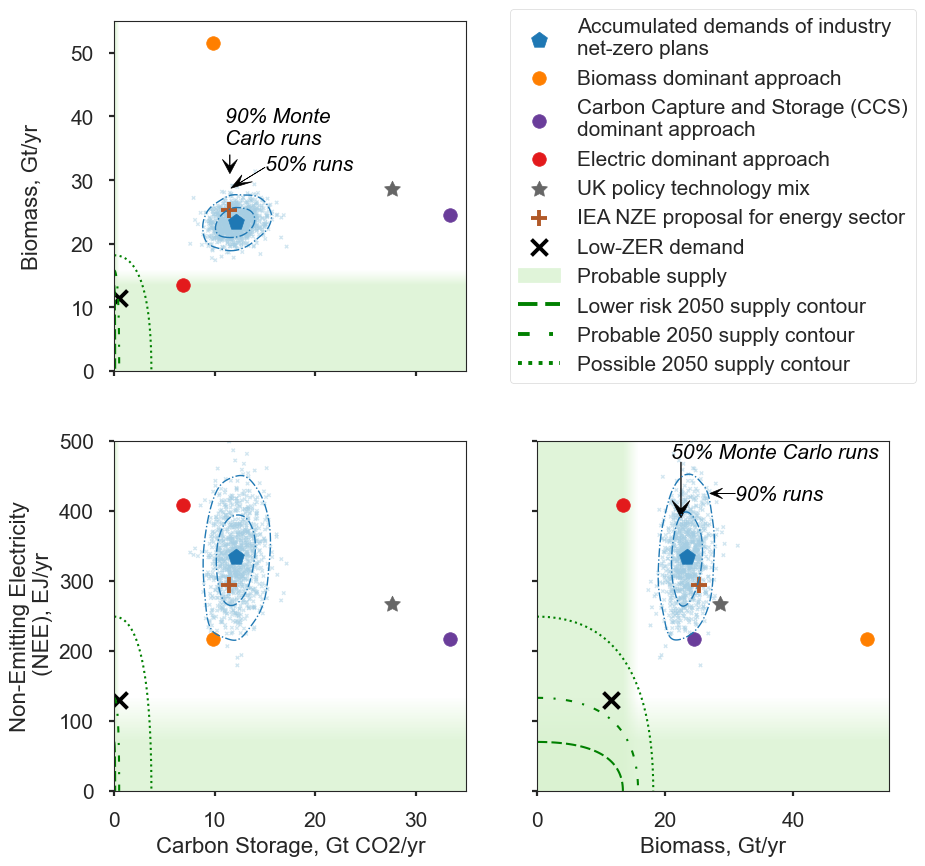

In [30]:
pairs = [("Biomass", "Carbon Storage"), ("NEE", "Carbon Storage"), ("NEE", "Biomass")]
fig, axes = plt.subplots(2, 2,  sharey='row', figsize=(10, 10), sharex='col')


axes[0, 0].set_ylabel('Biomass, Gt/yr\n ', 
                fontsize = AxisLabelFontSize, 
               fontweight = 'light')
axes[1, 0].set_ylabel('Non-Emitting Electricity\n (NEE), EJ/yr', 
                fontsize = AxisLabelFontSize, 
               fontweight = 'light')
# plt.xlabel('Carbon Storage, Gt CO2 (log scale)', fontsize = 21, fontweight = 'light')
axes[1, 0].set_xlabel('Carbon Storage, Gt CO2/yr', 
                fontsize = AxisLabelFontSize, 
               fontweight = 'light')
axes[1, 1].set_xlabel('Biomass, Gt/yr', 
                fontsize = AxisLabelFontSize, 
               fontweight = 'light')

########################### Thresholds Bands

Pastel_green = '#D9F2D0'
olive_green = (161/255, 215/255, 106/255)  # RGB (161,215,106)
whiter_green = (206/255, 234/255, 176/255) #CEEAB0
# Call the plot function and get the threshold line handles
band_patch = plot_supply_bands_FromZero_v2(axes, thresholds, band_color = Pastel_green)

#plot_pairwise_thresholds(fig, axes, thresholds)

################### Add Monte Carlo results to graph
# Note that the script 'UncertaintyMonteCarlo.py' can generate the MonteCarlo data, which is imported in this part of the code

Variance = '_Ten'
#MC_Results_IEA = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_IEANZE_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_IEA) 
MC_Results_Acc = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_Accumulated_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_Acc)
#MC_Results_LZERD = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_LZERD_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_LZERD)
#MC_Results_Elec = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_ElecDominant_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_Elec_L)
#MC_Results_Bio = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_BioDominant_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_Bio_L)
#MC_Results_CS = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_CCSDominant_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_CS_L)
#MC_Results_UKPol = Plot_MCResults("../Output/MonteCarlo/monte_carlo_results_UK_2050_10.csv", Opacity = MC_alpha, MarkerSize = SizeMC, MarkerColor=Color_UKPol_L)

# plot 50% and 90% contours
#plot_contour(axes, MC_Results_IEA, 0.5, Color_IEA_dark)
plot_contour(axes, MC_Results_Acc, 0.5, Color_Acc_dark)
#plot_contour(axes, MC_Results_LZERD, 0.5, 'black')
#plot_contour(axes, MC_Results_Elec, 0.5, Color_Elec)
#plot_contour(axes, MC_Results_Bio, 0.5, Color_Bio)
#plot_contour(axes, MC_Results_CS, 0.5, Color_CCS)
#plot_contour(axes, MC_Results_UKPol, 0.5, Color_UKPol)

#plot_contour(axes, MC_Results_IEA, 0.1, Color_IEA_dark)
plot_contour(axes, MC_Results_Acc, 0.1, Color_Acc_dark)
#plot_contour(axes, MC_Results_LZERD, 0.1, 'black')
#plot_contour(axes, MC_Results_Elec, 0.1, Color_Elec)
#plot_contour(axes, MC_Results_Bio, 0.1, Color_Bio)
#plot_contour(axes, MC_Results_CS, 0.1, Color_CCS)
#plot_contour(axes, MC_Results_UKPol, 0.1, Color_UKPol)
########################### Thresholds Contours

Styles = {
    "today": "--",
    "lower_risk": (0, (5, 2)),  # dashed
    "likely": (0, (3, 5, 1, 5)),  # dot-dash
    "possible": ':'  # dotted
}
contour_handles = plot_likely_contours(axes, thresholds, styles=Styles, contour_levels=("lower_risk", "likely", "possible"),)

########################### PLOT MODEL RUNS

ModelValue = Plot_ModelZERs(axes, ZERs_Accumulated, MarkerShape = (5, 0), MarkerSize = Size_Acc, MarkerColor = Color_Acc_dark)
UKPol = Plot_ModelZERs(axes, ZERs_UKPol, MarkerShape = (5, 1), MarkerSize = SizeUKPol, MarkerColor = Color_UKPol)
LZERD = Plot_ModelZERs(axes, ZERs_LZERD, MarkerShape = 'x', MarkerSize = SizeLZERD, MarkerColor = Color_LZERD_dark)
IEAZER = Plot_ModelZERs(axes, ZERs_IEAZER, MarkerShape = '+', MarkerSize = SizeIEA, MarkerColor = Color_IEA_dark)
BioDom = Plot_ModelZERs(axes, ZERs_BioDom, MarkerShape = 'o', MarkerSize = SizeCartoons, MarkerColor = Color_Bio)
CCSDom = Plot_ModelZERs(axes, ZERs_CCSDom, MarkerShape = 'o', MarkerSize = SizeCartoons, MarkerColor = Color_CCS)
ElecDom = Plot_ModelZERs(axes, ZERs_ElecDom, MarkerShape = 'o', MarkerSize = SizeCartoons, MarkerColor = Color_Elec)

 
# Set the axis limits

axes[0, 0].set_ylim(0, MaxBio)
axes[1, 0].set_xlim(0, MaxCS)
axes[1, 0].set_ylim(0, MaxNEE)
axes[1, 1].set_xlim(0, MaxBio)

axes[0, 0].tick_params(labelsize=AxisFontSize)
axes[1, 0].tick_params(labelsize=AxisFontSize)
axes[1, 1].tick_params(labelsize=AxisFontSize)

# create legend

# Combine all handles (existing + supply bands + contours)
all_handles = [
    ModelValue, 
    BioDom, 
    CCSDom, 
    ElecDom, 
    UKPol, 
    IEAZER, 
    LZERD,
    band_patch,                      # From plot_supply_bands()
    *contour_handles                # From plot_likely_contours()
]

# Corresponding labels
all_labels = [
    'Accumulated demands of industry\nnet-zero plans', 
    'Biomass dominant approach', 
    'Carbon Capture and Storage (CCS)\ndominant approach', 
    'Electric dominant approach', 
    'UK policy technology mix', 
    'IEA NZE proposal for energy sector', 
    'Low-ZER demand',
    'Probable supply',                    # patch label
    'Lower risk 2050 supply contour',           # dashed line
    'Probable 2050 supply contour',               # dash-dot line
    'Possible 2050 supply contour'              # dotted line
]

# Apply updated legend to axes[0, 1]
axes[0, 1].legend(
    all_handles,
    all_labels,
    loc='center',
    fontsize=TextFontSize
)

axes[0, 1].axis('off')
# Add annotations

axes[0,0].text(11, 35, '90% Monte\nCarlo runs', fontsize=TextFontSize, wrap=True, style='oblique', color = 'black', fontweight = 'light', 
          ha = 'left', va = 'bottom')

axes[0,0].text(15, 31, '50% runs', fontsize=TextFontSize, wrap=True, style='oblique', color = 'black', fontweight = 'light', 
          ha = 'left', va = 'bottom')

axes[0,0].arrow(11.5, 34, 0, -3, head_width=1.5, overhang = 0.5, length_includes_head =True, color='black')
axes[0,0].arrow(15, 32, -3.4, -3.3, head_width=1.5, overhang = 0.5, length_includes_head =True, color='black')

axes[1,1].text(31, 410, '90% runs', fontsize=TextFontSize, wrap=True, style='oblique', color = 'black', fontweight = 'light', 
          ha = 'left', va = 'bottom')
axes[1,1].arrow(31, 425, -4, 0, head_width=15, head_length = 2, overhang = 0.5, length_includes_head =True, color='black')

axes[1,1].text(21, 470, '50% Monte Carlo runs', fontsize=TextFontSize, wrap=True, style='oblique', color = 'black', fontweight = 'light', 
          ha = 'left', va = 'bottom')

axes[1,1].arrow(22.5, 470, 0, -80, head_width=2.8, head_length = 25, overhang = 0.5, length_includes_head =True, color='black')


rcParams['pdf.fonttype'] = 42  # Export text as text, not paths

# plt.tight_layout()
plt.savefig("../Output/Figure3-FeasibilityRegion.png", 
                            dpi = 600, bbox_inches = 'tight', facecolor='white', transparent=False)

plt.savefig("../Output/Figure3-FeasibilityRegion.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [33]:
################################################
# Compute MC statisics
# Note that this data is imported higher up in the script - the data can be generated using the UncertaintyMonteCarlo.py script


#Results_IEA_mean = np.mean(MC_Results_IEA)
#Results_IEA_SD = np.std(MC_Results_IEA) # standard deviation of results
#Results_IEA_SDrelative = Results_IEA_SD/Results_IEA_mean # coefficient of varation = relative standard deviation


Results_Acc_mean = np.mean(MC_Results_Acc)
Results_Acc_SD = np.std(MC_Results_Acc) # standard deviation of results
Results_Acc_SDrelative = Results_Acc_SD/Results_Acc_mean # coefficient of varation = relative standard deviation


#Results3_mean = np.mean(MC_Results_LZERD)
#Results3_SD = np.std(MC_Results_LZERD) # standard deviation of results
#Results3_SDrelative = Results3_SD/Results3_mean # coefficient of varation = relative standard deviation
 